# 04 — So sánh Trans2Vec và Hui2Vec, và đóng góp mới

Notebook này đọc `results.csv` (do notebook 02 và 03 ghi) để:

1. So sánh Trans2Vec với Hui2Vec trên 2 dataset.
2. Trình bày **đóng góp mới**: nhãn của dataset Food gần như chỉ phụ thuộc vào số lần khách đi mua hàng, nên độ dài giỏ hàng một mình đã phân loại tốt hơn Trans2Vec.
3. Kết luận.

In [ ]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

from utils import (DATA, PROCESSED, FIGURES, RESULTS_CSV, read_labeled, read_utility_db, doc2vec,
                   baselines, log_results, joint_docs, separate_pattern_tokens, nice)

res = pd.read_csv(RESULTS_CSV)
food_split = json.load(open(PROCESSED / "food_split.json"))
fm_split = json.load(open(PROCESSED / "foodmart_split.json"))


def pm(mean, std, runs):
    return f"{mean:.2f} ± {std:.2f}" if runs > 1 else f"{mean:.2f}"

## 1. Trans2Vec và Hui2Vec trên 2 dataset

Mỗi ô là accuracy `trung bình ± độ lệch chuẩn` (%) qua 10 lần chạy. Ô in đậm là phương pháp tốt nhất của từng dataset. TRANS-IT được chạy ở cả notebook 02 và 03; bảng dùng lần chạy ở notebook 02.

In [7]:
order = ["BOW", "TF-IDF", "TRANS-IT", "TRANS-FI", "TRANS-HUI",
         "Trans2Vec-IND", "Trans2Vec-JOI", "Hui2Vec-IND", "Hui2Vec-JOI"]
table = res[(res["method"] != "TRANS-IT") | (res["setting"] == "Trans2Vec")]
table = table[table["method"].isin(order)]

wide_num = table.pivot(index="method", columns="dataset", values="AC").reindex(order)
wide_txt = pd.DataFrame({
    ds: [pm(r.AC, r.AC_std, r.runs) for r in table[table["dataset"] == ds].set_index("method").reindex(order).itertuples()]
    for ds in ["Food", "Foodmart"]
}, index=order)
wide_txt.index.name = "Phương pháp"
bold = wide_num.eq(wide_num.loc[["Trans2Vec-IND", "Trans2Vec-JOI", "Hui2Vec-IND", "Hui2Vec-JOI"]].max())
(wide_txt.reset_index().style.hide(axis="index")
 .apply(lambda col: ["font-weight: bold" if col.name in bold and bold[col.name].iloc[i] else "" for i in range(len(col))])
 .set_caption("Accuracy (%) của mọi phương pháp trên 2 dataset"))

Phương pháp,Food,Foodmart
BOW,62.12,81.52
TF-IDF,64.50,70.77
TRANS-IT,67.24 ± 0.43,86.28 ± 0.50
TRANS-FI,70.00 ± 0.58,86.03 ± 0.35
TRANS-HUI,69.49 ± 0.84,78.36 ± 0.61
Trans2Vec-IND,68.79 ± 0.95,86.40 ± 0.33
Trans2Vec-JOI,70.25 ± 0.65,82.66 ± 0.39
Hui2Vec-IND,67.65 ± 1.18,87.79 ± 0.35
Hui2Vec-JOI,70.31 ± 0.51,82.57 ± 0.70


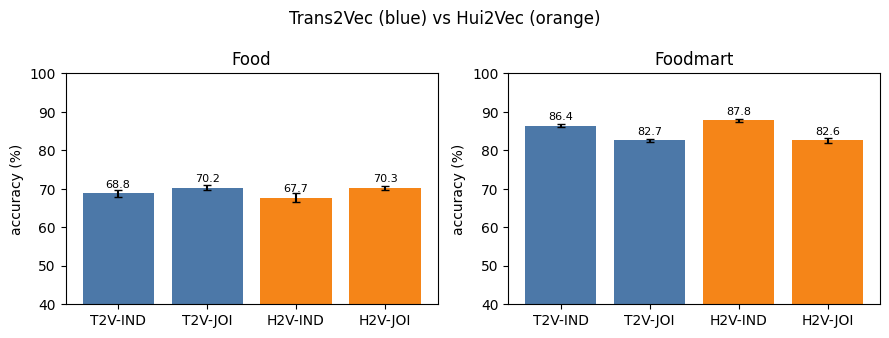

Food: Hui2Vec-JOI − Trans2Vec-JOI = +0.06 điểm, Hui2Vec-IND − Trans2Vec-IND = -1.14 điểm
Foodmart: Hui2Vec-JOI − Trans2Vec-JOI = -0.09 điểm, Hui2Vec-IND − Trans2Vec-IND = +1.39 điểm


In [8]:
main = ["Trans2Vec-IND", "Trans2Vec-JOI", "Hui2Vec-IND", "Hui2Vec-JOI"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, ds in zip(axes, ["Food", "Foodmart"]):
    sub = table[(table["dataset"] == ds) & table["method"].isin(main)].set_index("method").reindex(main)
    ax.bar(range(4), sub["AC"], yerr=sub["AC_std"], color=["#4C78A8", "#4C78A8", "#F58518", "#F58518"], capsize=3)
    ax.set_xticks(range(4))
    ax.set_xticklabels(["T2V-IND", "T2V-JOI", "H2V-IND", "H2V-JOI"])
    ax.set_ylim(40, 100)
    ax.set_title(ds)
    ax.set_ylabel("accuracy (%)")
    for k, v in enumerate(sub["AC"]):
        ax.text(k, v + 1.5, f"{v:.1f}", ha="center", fontsize=8)
fig.suptitle("Trans2Vec (blue) vs Hui2Vec (orange)")
fig.tight_layout()
fig.savefig(FIGURES / "trans2vec_vs_hui2vec.png", dpi=150)
plt.show()

ac = table.pivot(index="method", columns="dataset", values="AC")
for ds in ["Food", "Foodmart"]:
    print(f"{ds}: Hui2Vec-JOI − Trans2Vec-JOI = {ac.loc['Hui2Vec-JOI', ds] - ac.loc['Trans2Vec-JOI', ds]:+.2f} điểm, "
          f"Hui2Vec-IND − Trans2Vec-IND = {ac.loc['Hui2Vec-IND', ds] - ac.loc['Trans2Vec-IND', ds]:+.2f} điểm")

## 2. Đóng góp mới: nhãn của Food được quyết định bởi số lần đi mua

### 2.1 Độ dài giỏ hàng một mình đã thắng Trans2Vec

Ta thêm một baseline chỉ dùng **một feature duy nhất là độ dài giỏ hàng** (log của số item), cũng phân loại bằng Linear SVM C = 1 trên đúng tập train/test.

In [10]:
docs_food, y_food = read_labeled(DATA / "food" / "food.txt")
fm = read_utility_db(DATA / "utility" / "foodmart.txt")
docs_fm = [[str(i) for i in t[0]] for t in fm]
y_fm = pd.read_csv(PROCESSED / "foodmart_labels.csv")["label"].to_numpy()

rows = []
for ds, docs, y, sp in [("Food", docs_food, y_food, food_split), ("Foodmart", docs_fm, y_fm, fm_split)]:
    b = baselines(docs, y, np.array(sp["train"]), np.array(sp["test"]))
    b = b[b["method"] == "LENGTH-ONLY"]
    log_results(b, ds, "Contribution")
    best = table[(table["dataset"] == ds) & table["method"].isin(main)].sort_values("AC").iloc[-1]
    rows.append({"Dataset": ds, "LENGTH-ONLY AC (%)": b["AC"].iloc[0],
                 "Embedding tốt nhất": best["method"], "Embedding tốt nhất AC (%)": best["AC"],
                 "LENGTH-ONLY hơn": b["AC"].iloc[0] - best["AC"]})
nice(pd.DataFrame(rows), caption="Chỉ dùng độ dài giỏ so với embedding tốt nhất (cách chia train/test cố định)")

Dataset,LENGTH-ONLY AC (%),Embedding tốt nhất,Embedding tốt nhất AC (%),LENGTH-ONLY hơn
Food,73.38,Hui2Vec-JOI,70.31,3.07
Foodmart,87.08,Hui2Vec-IND,87.79,-0.71


Trên Food, một feature duy nhất (độ dài) ngang hoặc vượt mọi embedding. Trên Foodmart điều này dễ hiểu vì nhãn được định nghĩa từ tổng utility, vốn tăng theo số món. Nhưng Food dùng nhãn gốc của bài báo, nên câu hỏi là: **vì sao độ dài lại quyết định nhãn "có dùng khuyến mãi"?**

### 2.2 Cơ chế sinh nhãn của Food

Nhãn `yes` nghĩa là khách **có ít nhất một lượt mua** chứa hàng khuyến mãi (notebook 01). Giả thuyết của nhóm: trong CSDL FoodMart, mỗi lượt mua có hàng khuyến mãi với một xác suất cố định p, độc lập với khách hàng và với món hàng. Khi đó một khách đi mua n lần sẽ có nhãn `yes` với xác suất

$$P(\text{yes} \mid n) = 1 - (1 - p)^n$$

Nếu giả thuyết đúng, nhãn chỉ phụ thuộc vào **số lượt mua n**, không phụ thuộc vào món nào nằm trong giỏ. Khách đi mua nhiều lần thì giỏ gộp dài hơn, nên độ dài giỏ "mượn" được thông tin này.

Ta kiểm tra trên toàn bộ CSDL FoodMart (một lượt mua = một khách, một ngày, một cửa hàng).

Toàn bộ CSDL: 8,842 khách hàng, 58,381 lượt mua
p = tỉ lệ lượt mua có hàng khuyến mãi = 0.258


Số lượt mua,Số khách,P(yes) thực tế,P(yes) theo mô hình,Chênh lệch
1,"1,225",0.266,0.258,0.008
2,"1,203",0.447,0.450,-0.003
3,"1,163",0.610,0.592,0.018
4–5,"1,896",0.730,0.732,-0.001
6–8,"1,372",0.872,0.864,0.007
> 8,"1,983",0.971,0.978,-0.006


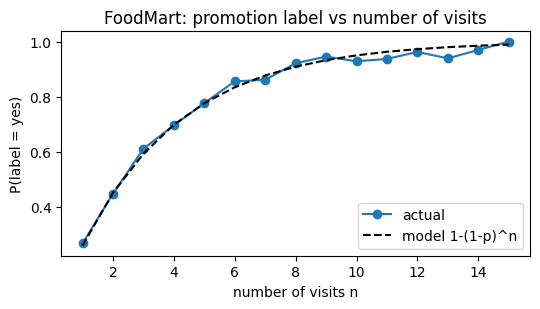

Chênh lệch tuyệt đối lớn nhất giữa thực tế và mô hình: 0.018


In [11]:
sales = pd.read_csv(DATA / "foodmart_db" / "sales.csv")
sales["promo"] = sales["promotion_id"].notna()
visits = sales.groupby(["customer_id", "time_id", "store_id"])["promo"].any().reset_index()
p_visit = visits["promo"].mean()

cust = visits.groupby("customer_id").agg(n_visits=("promo", "size"), yes=("promo", "any"))
cust["null"] = 1 - (1 - p_visit) ** cust["n_visits"]
print(f"Toàn bộ CSDL: {len(cust):,} khách hàng, {len(visits):,} lượt mua")
print(f"p = tỉ lệ lượt mua có hàng khuyến mãi = {p_visit:.3f}")

VISIT_BINS = [0, 1, 2, 3, 5, 8, 1000]
VISIT_NAMES = ["1", "2", "3", "4–5", "6–8", "> 8"]
cust["group"] = pd.cut(cust["n_visits"], VISIT_BINS, labels=VISIT_NAMES)
null_tab = cust.groupby("group", observed=True).agg(n=("yes", "size"), actual=("yes", "mean"), null=("null", "mean")).reset_index()
null_tab.columns = ["Số lượt mua", "Số khách", "P(yes) thực tế", "P(yes) theo mô hình"]
null_tab["Chênh lệch"] = null_tab["P(yes) thực tế"] - null_tab["P(yes) theo mô hình"]
display(nice(null_tab, digits=3, caption="Tỉ lệ khách có nhãn yes: thực tế so với mô hình 1 − (1 − p)ⁿ"))

by_n = cust[cust["n_visits"] <= 15].groupby("n_visits")["yes"].mean()
n_grid = np.arange(1, 16)
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(by_n.index, by_n.to_numpy(), marker="o", label="actual")
ax.plot(n_grid, 1 - (1 - p_visit) ** n_grid, linestyle="--", color="black", label="model 1-(1-p)^n")
ax.set_xlabel("number of visits n")
ax.set_ylabel("P(label = yes)")
ax.set_title("FoodMart: promotion label vs number of visits")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "food_label_mechanism.png", dpi=150)
plt.show()
print(f"Chênh lệch tuyệt đối lớn nhất giữa thực tế và mô hình: {null_tab['Chênh lệch'].abs().max():.3f}")

Mô hình chỉ có **một tham số** p mà khớp với thực tế đến khoảng 0,02 ở mọi nhóm. Nghĩa là nhãn khuyến mãi trong FoodMart được sinh gần như ngẫu nhiên theo từng lượt mua: biết số lượt mua là biết gần hết những gì có thể biết về nhãn.

Khách đi mua nhiều lần thì giỏ gộp dài hơn. Số lượt mua không có trong `food.txt`, nhưng mỗi giỏ Food khớp đúng một khách trong CSDL (notebook 01), nên ta đo được tương quan giữa độ dài giỏ và số lượt mua.

In [ ]:
cust_items = sales.groupby("customer_id")["product_id"].apply(lambda s: frozenset(map(str, s)))
basket_to_cust = {items: cid for cid, items in cust_items.items()}
food_cust = np.array([basket_to_cust[frozenset(d)] for d in docs_food])
food_visits = cust.loc[food_cust, "n_visits"].to_numpy()
food_len = np.array([len(d) for d in docs_food])
assert (cust.loc[food_cust, "yes"].to_numpy() == (y_food == "yes")).all()

print(f"Tương quan Spearman giữa độ dài giỏ và số lượt mua: {spearmanr(food_len, food_visits)[0]:.3f}")

Tương quan rất cao, nên độ dài giỏ thay thế được cho số lượt mua. Đó là lý do LENGTH-ONLY phân loại tốt.

### 2.3 Kiểm tra trên 20 cách chia ngẫu nhiên

Kết quả ở mục 2.1 dựa trên một cách chia 800 mẫu. Ta lặp lại phép so sánh LENGTH-ONLY với Trans2Vec-JOI trên 20 cách chia ngẫu nhiên có phân tầng (cùng tỉ lệ 3.200/800). Embedding được học không giám sát trên toàn bộ 4.000 giao dịch như code gốc, nên chỉ cần học 3 lần (3 seed) rồi dùng lại: cách chia thứ k dùng seed k mod 3. Feature được chuẩn hoá (StandardScaler) trước Linear SVM, nên số liệu có thể lệch nhẹ so với mục 1.

In [ ]:
docs_fi_food, _ = read_labeled(DATA / "food" / "food_trans_fis_0.002.txt")
docs_joi = joint_docs(docs_food, separate_pattern_tokens(docs_fi_food))     # same docs as notebook 02
SEEDS = [0, 1, 2]
emb = [doc2vec(docs_joi, seed=s) for s in SEEDS]
X_len = np.log1p(food_len)[:, None]


def accuracy(X, tr, te):
    clf = make_pipeline(StandardScaler(), LinearSVC(C=1.0, max_iter=5000)).fit(X[tr], y_food[tr])
    return 100 * np.mean(clf.predict(X[te]) == y_food[te])


sss = StratifiedShuffleSplit(n_splits=20, test_size=800, random_state=0)
rows = []
for k, (tr_k, te_k) in enumerate(sss.split(np.zeros(len(y_food)), y_food)):
    rows.append({"LENGTH-ONLY": accuracy(X_len, tr_k, te_k),
                 "Trans2Vec-JOI": accuracy(emb[k % len(SEEDS)], tr_k, te_k)})
multi = pd.DataFrame(rows)

display(nice(pd.DataFrame({
    "Phương pháp": multi.columns,
    "Accuracy TB (%)": multi.mean().to_numpy(),
    "Độ lệch chuẩn": multi.std().to_numpy(),
}), caption="Food: accuracy trên 20 cách chia train/test ngẫu nhiên"))
wins = int((multi["LENGTH-ONLY"] > multi["Trans2Vec-JOI"]).sum())
print(f"LENGTH-ONLY hơn Trans2Vec-JOI trung bình {(multi['LENGTH-ONLY'] - multi['Trans2Vec-JOI']).mean():.2f} điểm, "
      f"thắng {wins}/20 cách chia")

## 3. Kết luận

**Tái thực nghiệm Trans2Vec trên Food (notebook 02).** Kết quả lệch so với Bảng 2 của bài không quá 2,3 điểm, lệch nhiều nhất ở Trans2Vec-JOI (70,25% so với 72,51%). Thứ hạng giữ đúng như bài: TRANS-FI (70,00%) cao hơn TRANS-IT (67,24%), và Trans2Vec-JOI cao nhất trong 4 phương pháp embedding. Phần lệch đến từ việc dùng gensim 4 thay vì 3.4 và bài không công bố seed.

**Trans2Vec và Hui2Vec (mục 1).** Trên cả 2 dataset, hai phương pháp chênh nhau không quá 1,4 điểm. Hui2Vec-JOI hơn Trans2Vec-JOI 0,06 điểm trên Food và kém 0,09 điểm trên Foodmart, nhỏ hơn độ lệch chuẩn giữa các lần chạy. Nhóm không thấy ưu thế lớn của Hui2Vec như bài Hui2Vec báo cáo, kể cả trên Foodmart, nơi nhãn được định nghĩa từ utility và lẽ ra có lợi cho Hui2Vec.

**Đóng góp mới (mục 2).** Trên Food, chỉ dùng độ dài giỏ hàng đã đạt 73,38%, cao hơn mọi embedding (tốt nhất là Hui2Vec-JOI với 70,31%). Kết quả giữ vững trên 20 cách chia ngẫu nhiên: LENGTH-ONLY thắng Trans2Vec-JOI 19/20 lần. Nguyên nhân: nhãn `yes` nghĩa là khách có ít nhất một lượt mua có hàng khuyến mãi, mà mỗi lượt mua có khuyến mãi với xác suất gần như cố định p ≈ 0,26. Mô hình P(yes | n) = 1 − (1 − p)ⁿ khớp thực tế với sai số không quá 0,02, và độ dài giỏ tương quan 0,95 với số lượt mua. Vì vậy benchmark Food chủ yếu đo độ dài giỏ hàng, chưa đo được khả năng học biểu diễn từ các món hàng.

**Hạn chế.**
- Nhãn Foodmart do nhóm tự định nghĩa (TU ≥ trung vị) vì bài Hui2Vec không công bố nhãn. Nhãn này cũng tăng theo số món, nên LENGTH-ONLY trên Foodmart (87,08%) gần bằng embedding tốt nhất.
- HUI trên Food giới hạn tối đa 2 item, vì giỏ quá dài làm số HUI bùng nổ (notebook 03).
- Elbow method được cụ thể hoá thành quy tắc "ngưỡng đầu tiên mà số pattern tăng gấp đôi".
- Số liệu ở đây lấy từ lần chạy của nhóm. Doc2Vec có yếu tố ngẫu nhiên nên chạy lại có thể lệch nhẹ.